# EDA — encontros e amizade no OpiniOn (CC2, experimento Last.fm)

**Pergunta do modelo:** dado que dois usuários acabaram de se encontrar, qual a chance de **serem amigos** (no Last.fm)?

Este notebook explora o dataset produzido pelo pipeline (`data/processed/`) para responder:

1. Os dados fazem sentido? (volumes, distribuições, linha do tempo)
2. O que está associado a um encontro envolver dois amigos? (encontro, contexto, compatibilidade de gosto, perfil)
3. Quais contextos e perfis concentram mais amizades — pauta da sessão com o Design
4. Que cuidados o modelo (CC3 em diante) precisa ter?

> ⚠️ **O que é real e o que é simulado.** Usuários, artistas, escutas (viram notas 1–5 por quintil) e **amizades** vêm do
> HetRec 2011 Last.fm (`docs/fontes_dados.md`) e são reais; o rótulo `conectou` é a amizade real (estática).
> **Encontros e pulseira são simulados** (`config/simulacao.yaml`) e sorteados **sem olhar a amizade**.
> Logo, o que aparece aqui sobre duração, proximidade, local, dia e hora vem das premissas da simulação; só a relação
> entre **gosto** e amizade vem dos dados reais. Os números do texto se referem ao bootstrap padrão (semente 42).
> As variáveis de relação (`algum_segue`, `seguem_mutuamente`, `interacoes_anteriores_par`, `interagiram_antes`,
> `conexoes_min/max`) são o próprio rótulo (ou derivam dele) e ficam fora do modelo; também não existe mais o recorte "só
> desconhecidos".

**Para rodar:** `pip install -r requirements-analise.txt`, rode o pipeline (`python -m opinion.pipeline.executar` ou a DAG) e depois *Run All*.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, STAGING = RAIZ / "data" / "processed", RAIZ / "data" / "staging"
VERDADE = RAIZ / "data" / "bootstrap" / "verdade_simulacao_NAO_USAR_COMO_FEATURE"

# estilo: uma cor por papel, grade discreta, sem bordas desnecessárias
AZUL, LARANJA, CINZA, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#9a9893", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (8, 3.6), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10, "legend.frameon": False,
})
pct = lambda x: f"{100 * x:.1f}%"

def eixo_pct(ax, eixo="y"):
    a = ax.yaxis if eixo == "y" else ax.xaxis
    a.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    a.set_major_formatter(lambda v, _: f"{100 * v:.0f}%")

def barras_taxa(ax, serie, titulo, ref=None, cor=AZUL, rotulo_ref="média geral"):
    """Barras de taxa de conexão com rótulo em cada barra e linha de referência."""
    x = np.arange(len(serie))
    ax.bar(x, serie.values, color=cor, width=0.62, zorder=2)
    for i, v in enumerate(serie.values):
        ax.text(i, v, pct(v), ha="center", va="bottom", fontsize=9, color=TINTA)
    ax.set_xticks(x, [str(i) for i in serie.index])
    eixo_pct(ax)
    if ref is not None:
        ax.axhline(ref, color=CINZA, lw=1.2, ls="--", zorder=1, label=f"{rotulo_ref}: {pct(ref)}")
        ax.legend(loc="upper left", fontsize=8.5)
    ax.set_title(titulo)
    ax.set_ylim(0, max(serie.max(), ref or 0) * 1.35)

dm = pd.read_parquet(PROC / "dataset_modelo.parquet")
todos = pd.read_parquet(PROC / "features_encontros.parquet")
meta = json.loads((PROC / "metadados.json").read_text())
dm["duracao_min"] = np.exp(dm.log_duracao) / 60
dm["local"] = dm.local_original
print(f"{len(dm):,} encontros rotulados · {dm.par_id.nunique():,} pares · {len(meta['colunas_features'])} features")
print(f"Período: {dm.inicio.min():%d/%m/%Y} a {dm.inicio.max():%d/%m/%Y} · corte dos dados: {meta['corte_dos_dados']}")

162,897 encontros rotulados · 153,212 pares · 42 features
Período: 06/07/2026 a 27/09/2026 · corte dos dados: 2026-09-28 00:08:45


## 1. Visão geral e qualidade

O pipeline já barra problemas graves (a DAG falha se houver nulos, duplicatas ou taxa de conexão fora da faixa). Aqui conferimos o que sobrou.

In [2]:
resumo = pd.DataFrame(meta["por_split"]).T[["encontros", "pares", "taxa_conexao"]]
resumo["taxa_conexao"] = resumo.taxa_conexao.map(lambda x: f"{100 * x:.2f}%")
display(resumo.loc[["treino", "validacao", "teste"]])
print(f"Encontros ainda sem label: {meta['encontros_sem_label_ainda']:,} (o rótulo é a amizade, sempre disponível)")
print(f"Positivos (pares de amigos que se encontraram): {int(dm.conectou.sum()):,} de {len(dm):,} encontros "
      f"({100 * dm.conectou.mean():.2f}%) em {dm.par_id.nunique():,} pares")
print(f"Label do pipeline x referência da simulação: {pct(meta['concordancia_label_referencia'])} de concordância")
print(f"Nulos nas features: {int(dm[meta['colunas_features']].isna().sum().sum())}")

,encontros,pares,taxa_conexao
treino,114033.0,107249.0,0.76%
validacao,24367.0,22981.0,0.74%
teste,24497.0,22982.0,0.75%


Encontros ainda sem label: 0 (o rótulo é a amizade, sempre disponível)
Positivos (pares de amigos que se encontraram): 1,235 de 162,897 encontros (0.76%) em 153,212 pares
Label do pipeline x referência da simulação: 100.0% de concordância
Nulos nas features: 0


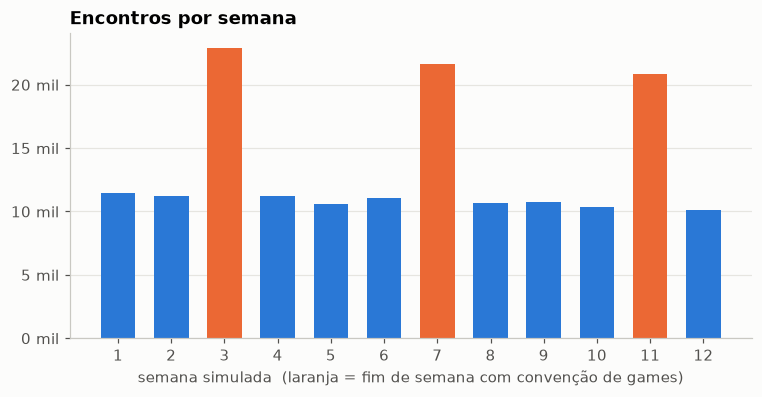

Taxa de amizade por semana: S1:0.69% S2:0.74% S3:0.80% S4:0.86% S5:0.72% S6:0.67% S7:0.81% S8:0.69% S9:0.61% S10:0.79% S11:0.83% S12:0.72%


In [3]:
fig, ax = plt.subplots()
sem = dm.groupby("semana").agg(n=("encontro_id", "size"), taxa=("conectou", "mean"))
cores = [LARANJA if s in (3, 7, 11) else AZUL for s in sem.index]
ax.bar(sem.index, sem.n, color=cores, width=0.65, zorder=2)
ax.set_xticks(sem.index)
ax.set_title("Encontros por semana")
ax.set_xlabel("semana simulada  (laranja = fim de semana com convenção de games)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f} mil")
plt.show()
print("Taxa de amizade por semana:", " ".join(f"S{s}:{100 * t:.2f}%" for s, t in sem.taxa.items()))

**Leitura.** O volume dobra nas semanas com convenção (3, 7 e 11), mas a **taxa de amizade fica estável** em torno de 0,6%–0,9% em todas as semanas (flutuação de amostragem: são ~100 positivos por semana). Como o split agora é **por par** (e não temporal), isso importa menos para dividir os dados, mas confirma que a base não muda ao longo do tempo. O problema é **extremamente desbalanceado** (1 positivo para ~130 negativos, prevalência ≈ 0,76%) — por isso a métrica principal é PR-AUC comparada com a prevalência, não acurácia nem ROC-AUC isolada.

## 2. Características do encontro

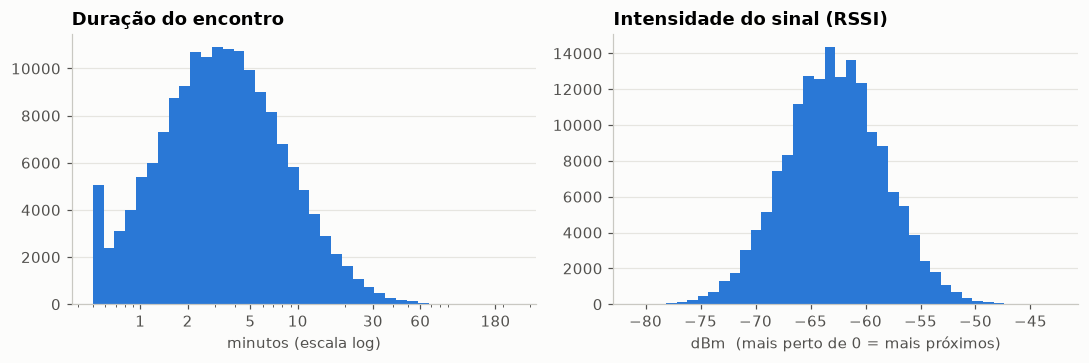

,encontros,duracao_mediana_min,rssi_medio
local,,,
campus,63799,2.0,-62.9
cinema,31469,5.0,-62.9
convencao_games,33396,6.0,-62.9
livraria,34233,3.0,-62.9


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.logspace(np.log10(0.5), np.log10(240), 40)
axs[0].hist(dm.duracao_min, bins=bins, color=AZUL, zorder=2)
axs[0].set_xscale("log"); axs[0].set_xticks([1, 2, 5, 10, 30, 60, 180], ["1", "2", "5", "10", "30", "60", "180"])
axs[0].set_title("Duração do encontro"); axs[0].set_xlabel("minutos (escala log)")
axs[1].hist(dm.rssi_medio, bins=40, color=AZUL, zorder=2)
axs[1].set_title("Intensidade do sinal (RSSI)"); axs[1].set_xlabel("dBm  (mais perto de 0 = mais próximos)")
plt.tight_layout(); plt.show()
display(dm.groupby("local").agg(encontros=("encontro_id", "size"), duracao_mediana_min=("duracao_min", "median"),
                                rssi_medio=("rssi_medio", "mean")).round(1))

**Leitura.** A duração tem cauda longa (de 30 s a horas); a mediana fica entre 2 e 6 min conforme o local, exatamente as premissas do simulador. O RSSI concentra-se entre −70 e −55 dBm (≈0,5–3 m) e tem média igual em todos os locais (−62,9 dBm). Nenhuma dessas distribuições vem de dados reais: servem para checar se o que o modelo recebe é plausível (documento de validação da simulação: 13 de 13 checagens OK).

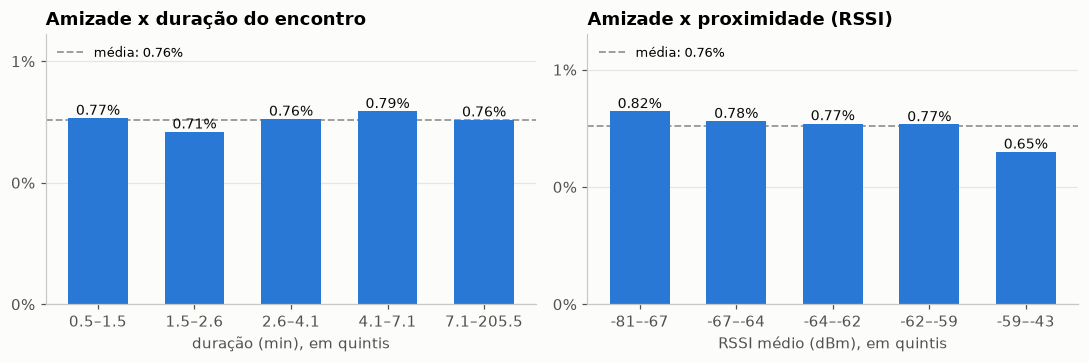

In [5]:
def quintis(serie, fmt="{:.1f}"):
    q = pd.qcut(serie, 5, duplicates="drop")
    return q, [f"{fmt.format(i.left)}–{fmt.format(i.right)}" for i in q.cat.categories]

def taxa_por(serie, rotulos_fn=quintis):
    q, nomes = rotulos_fn(serie)
    s = dm.groupby(q, observed=True).conectou.mean()
    s.index = nomes
    return s

def barras_taxa2(ax, s, titulo):
    """Como barras_taxa, mas com 2 casas decimais (a taxa é < 1%)."""
    x = np.arange(len(s))
    ax.bar(x, s.values, color=AZUL, width=0.62, zorder=2)
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{100 * v:.2f}%", ha="center", va="bottom", fontsize=9, color=TINTA)
    ax.set_xticks(x, [str(i) for i in s.index]); eixo_pct(ax)
    ax.axhline(dm.conectou.mean(), color=CINZA, lw=1.2, ls="--", zorder=1, label=f"média: {100 * dm.conectou.mean():.2f}%")
    ax.legend(loc="upper left", fontsize=8.5); ax.set_title(titulo)
    ax.set_ylim(0, max(s.max(), dm.conectou.mean()) * 1.4)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
barras_taxa2(axs[0], taxa_por(dm.duracao_min), "Amizade x duração do encontro")
axs[0].set_xlabel("duração (min), em quintis")
barras_taxa2(axs[1], taxa_por(dm.rssi_medio, lambda x: quintis(x, "{:.0f}")), "Amizade x proximidade (RSSI)")
axs[1].set_xlabel("RSSI médio (dBm), em quintis")
plt.tight_layout(); plt.show()

**Leitura.** Amizade **não varia com a duração** (0,71%–0,79% em todos os quintis, AUC univariada ≈ 0,50) e **não varia com a proximidade** (0,65%–0,82%; a pequena queda no quintil mais próximo é ruído: ~250 positivos por barra). Isso não é descoberta: os encontros foram sorteados sem olhar a amizade, então duração e RSSI **não podem** conter informação sobre o rótulo. É o comportamento esperado de um simulador independente e um bom teste de sanidade (se aparecesse padrão aqui, haveria vazamento). Na vida real, amigos provavelmente ficam mais tempo e mais perto; isso só poderá ser medido com os encontros reais dos testes do Design (semana 16).

## 3. Contexto — onde as amizades aparecem

Todos os encontros entram (não há mais separação "desconhecidos x amigos": a rede social é o próprio rótulo).

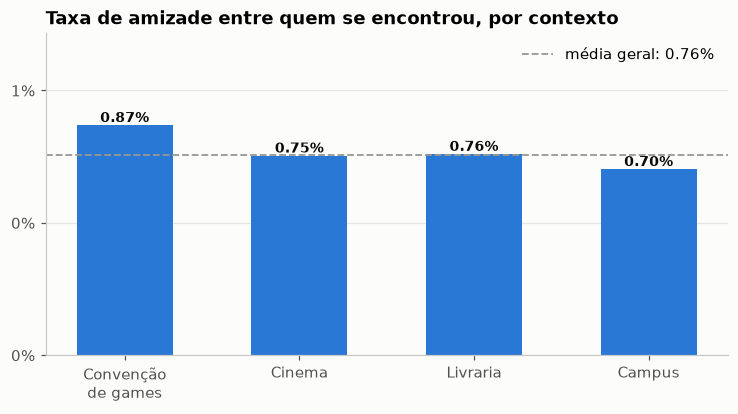

,encontros,positivos,taxa de amizade
local,,,
convencao_games,33396,290,0.87%
cinema,31469,237,0.75%
livraria,34233,260,0.76%
campus,63799,448,0.70%


In [6]:
ordem = ["convencao_games", "cinema", "livraria", "campus"]
nomes = ["Convenção\nde games", "Cinema", "Livraria", "Campus"]
t_todos = dm.groupby("local").conectou.mean().reindex(ordem)
n_loc = dm.groupby("local").size().reindex(ordem)
pos_loc = dm.groupby("local").conectou.sum().reindex(ordem)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(4)
ax.bar(x, t_todos, 0.55, color=AZUL, zorder=2)
for i in range(4):
    ax.text(x[i], t_todos.iloc[i], f"{100 * t_todos.iloc[i]:.2f}%", ha="center", va="bottom", fontsize=9, color=TINTA, weight="bold")
ax.axhline(dm.conectou.mean(), color=CINZA, ls="--", lw=1.2, label=f"média geral: {100 * dm.conectou.mean():.2f}%")
ax.set_xticks(x, nomes); eixo_pct(ax)
ax.set_title("Taxa de amizade entre quem se encontrou, por contexto"); ax.legend(loc="upper right"); ax.set_ylim(0, t_todos.max() * 1.4)
plt.show()
display(pd.DataFrame({"encontros": n_loc, "positivos": pos_loc.astype(int), "taxa de amizade": t_todos.map(lambda v: f"{100 * v:.2f}%")}))

**Leitura.** A taxa por contexto varia pouco: convenção 0,87%, livraria 0,76%, cinema 0,75% e campus 0,70% (média 0,76%). A diferença da convenção para o campus (~1,2×) é pequena, tem poucas centenas de positivos por barra e **não deve ser lida como "convenção converte mais"**: não há causa embutida no simulador — o local só decide quais usuários circulam onde (por persona), e essa mistura pode alterar levemente a densidade de amigos de quem frequenta cada lugar. Diferente da versão anterior (rótulo simulado), aqui **o contexto não é um bom preditor** e a política "convenção aberta, campus restrito" da seção 3.3 **não é sustentada por estes dados**; ela depende dos testes reais.

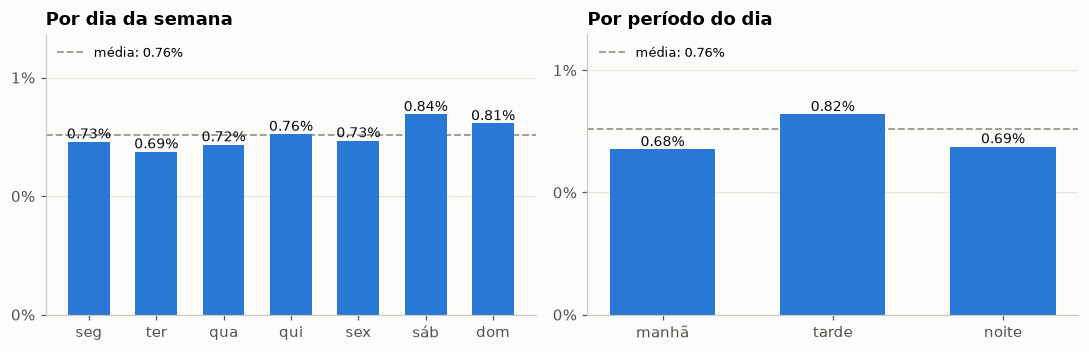

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
dias = dm.groupby(dm.inicio.dt.day_of_week).conectou.mean()
dias.index = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
barras_taxa2(axs[0], dias, "Por dia da semana")
per = dm.groupby(pd.cut(dm.hora, [-1, 11, 17, 23], labels=["manhã", "tarde", "noite"]), observed=True).conectou.mean()
barras_taxa2(axs[1], per, "Por período do dia")
plt.tight_layout(); plt.show()

**Leitura.** Dia e período do dia têm efeito pequeno e sem padrão claro (0,69%–0,84% por dia; fins de semana um pouco acima, coincidindo com a convenção, e a tarde um pouco acima da manhã e da noite). Como a simulação não liga horário à amizade, trata-se de variação amostral e de composição de público. Premissa a confrontar com os dados reais dos testes do Design (semana 16).

## 4. Compatibilidade de gosto

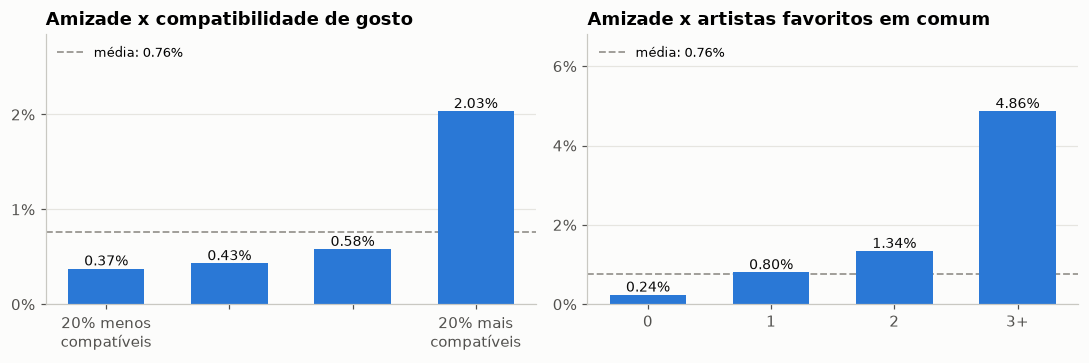

Encontros sem nenhum artista avaliado em comum: 43.4%


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
q = pd.qcut(dm.compat_score, 5, duplicates="drop")
s = dm.groupby(q, observed=True).conectou.mean()
s.index = ["20% menos\ncompatíveis"] + [""] * (len(s) - 2) + ["20% mais\ncompatíveis"]
barras_taxa2(axs[0], s, "Amizade x compatibilidade de gosto")
fav = dm.groupby(dm.favoritas_comuns.clip(upper=3)).conectou.mean()
fav.index = ["0", "1", "2", "3+"][:len(fav)]
barras_taxa2(axs[1], fav, "Amizade x artistas favoritos em comum")
plt.tight_layout(); plt.show()
print(f"Encontros sem nenhum artista avaliado em comum: {pct((dm.n_obras_comuns == 0).mean())}")

**Leitura — o principal sinal do experimento.** Aqui **o gosto musical importa**, e vem de dados reais: a taxa de amizade vai de ≈0,4% nos encontros menos compatíveis para ≈2,0% no quintil mais compatível (≈2,7× a média). Com **artistas favoritos em comum** o efeito é maior: 0,24% sem nenhum, 0,8% com 1, 1,3% com 2 e **4,9% com 3 ou mais** (6× a média); e por **artistas avaliados em comum** vai de 0,13% (nenhum) a 6,3% (11 ou mais). Ainda assim, em termos absolutos a amizade continua rara — mesmo no grupo mais compatível, 98% dos encontros não são entre amigos — então a regra "acender quando a compatibilidade passa de X" terá precisão baixa e é a referência a superar na seção 8. Cuidado de interpretação: usuários do Last.fm que são amigos tendem a ter gosto parecido (homofilia), e o simulador sorteia pares que se encontram de qualquer forma; isso mede quanto o gosto *se associa* à amizade, não o quanto um encontro *causa* uma amizade.

## 5. Repetição do par e artistas em comum

A relação social prévia (seguir, interagir) deixou de ser analisável: é o rótulo. Sobram a repetição de encontros do par (simulada) e o tamanho da interseção de gosto.

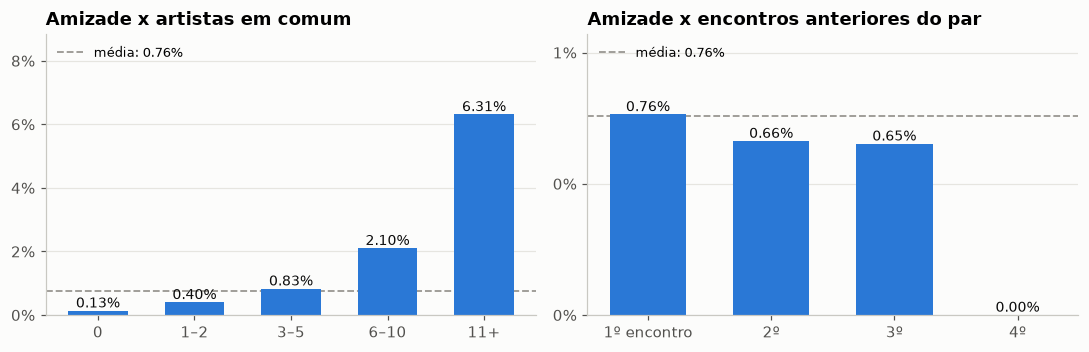

5.9% dos encontros são de um par que já tinha se encontrado antes.
Features de relação excluídas do modelo: conexoes_min, conexoes_max, algum_segue, seguem_mutuamente, interacoes_anteriores_par, interagiram_antes


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
oc = dm.groupby(pd.cut(dm.n_obras_comuns, [-1, 0, 2, 5, 10, 10_000], labels=["0", "1–2", "3–5", "6–10", "11+"]), observed=True).conectou.mean()
barras_taxa2(axs[0], oc, "Amizade x artistas em comum")
rep = dm.groupby(dm.n_encontros_anteriores_par.clip(upper=4)).conectou.mean()
rep.index = ["1º encontro", "2º", "3º", "4º", "5º+"][:len(rep)]
barras_taxa2(axs[1], rep, "Amizade x encontros anteriores do par")
plt.tight_layout(); plt.show()
print(f"{pct((dm.n_encontros_anteriores_par > 0).mean())} dos encontros são de um par que já tinha se encontrado antes.")
print("Features de relação excluídas do modelo:", ", ".join(c for c in todos.columns if c in ["algum_segue", "seguem_mutuamente", "interacoes_anteriores_par", "interagiram_antes", "conexoes_min", "conexoes_max"]))

**Leitura.** À esquerda, a mesma história da seção 4 vista pela interseção bruta de artistas: quanto mais artistas em comum, maior a taxa de amizade (de 0,13% para 6,3%). À direita, os encontros repetidos **não aumentam** a taxa (0,76% no 1º encontro; 0,65%–0,66% no 2º e 3º) — de novo, esperado numa simulação independente — e são poucos (5,9% dos encontros pertencem a um par que já havia se encontrado), o que mostra que o `n_encontros_anteriores_par` é quase irrelevante neste experimento. Consequência para o modelo: o split e a validação cruzada são feitos **por par** para que um mesmo par (com o mesmo rótulo estático) nunca fique dos dois lados, e as features de relação (rede e interações) permanecem **excluídas**.

## 6. Perfis

Dois olhares: **perfis observáveis** (tamanho do histórico no app) e **personas** (só existem porque o comportamento de circulação é simulado — servem para conversar com o Design, não entram no modelo). Atividade recente (últimos 28 dias) é constante: o Last.fm é um retrato estático, sem avaliações datadas.

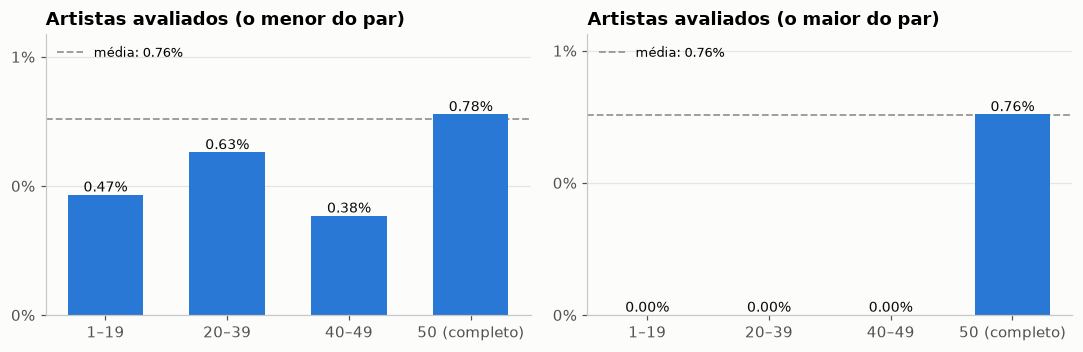

Atividade recente (avaliações nos últimos 28 dias): valores distintos = 1 (o Last.fm é um retrato estático: não há atividade datada)


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, col, tit in [(axs[0], "historico_min", "Artistas avaliados (o menor do par)"),
                     (axs[1], "historico_max", "Artistas avaliados (o maior do par)")]:
    a = dm.groupby(pd.cut(dm[col], [0, 19, 39, 49, 50], labels=["1–19", "20–39", "40–49", "50 (completo)"]), observed=True).conectou.mean()
    barras_taxa2(ax, a, tit)
plt.tight_layout(); plt.show()
print(f"Atividade recente (avaliações nos últimos 28 dias): valores distintos = {dm.atividade_max.nunique()} (o Last.fm é um retrato estático: não há atividade datada)")


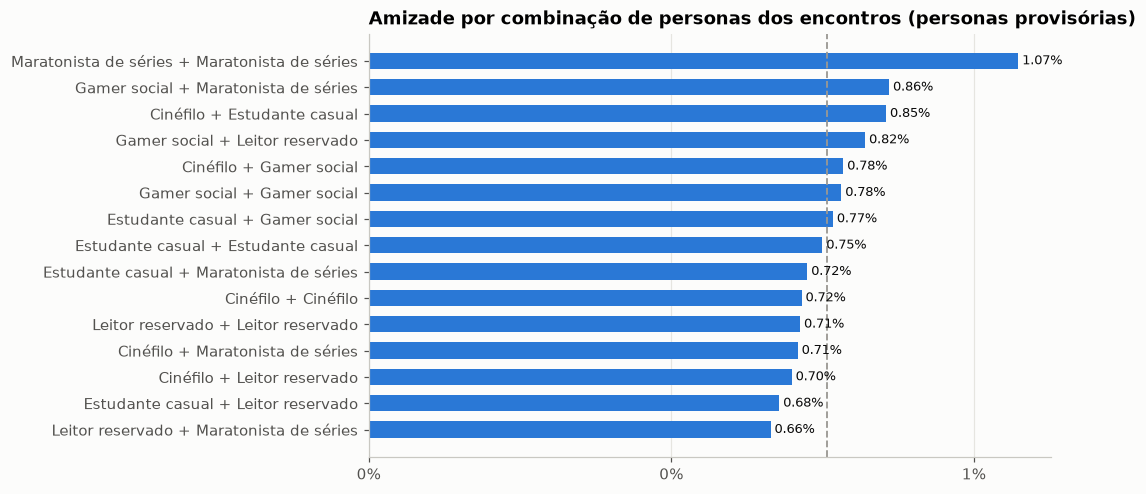

Positivos por combinação: min 12, máx 144  (poucos positivos por barra: leia com cautela)


In [11]:
pers = pd.read_csv(VERDADE / "usuarios_ocultos.csv").set_index("usuario_id").persona
nome = {"gamer_social": "Gamer social", "cinefilo": "Cinéfilo", "leitor_reservado": "Leitor reservado",
        "estudante_casual": "Estudante casual", "maratonista_series": "Maratonista de séries"}
d = dm.assign(pa=dm.usuario_a.map(pers).map(nome), pb=dm.usuario_b.map(pers).map(nome))
d["combinacao"] = [" + ".join(sorted(p)) for p in zip(d.pa, d.pb)]
g = d.groupby("combinacao").agg(encontros=("encontro_id", "size"), positivos=("conectou", "sum"), amizade=("conectou", "mean"))
g = g[g.encontros >= 1000].sort_values("amizade")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(np.arange(len(g)), g.amizade, color=AZUL, height=0.62, zorder=2)
ax.set_yticks(np.arange(len(g)), g.index); ax.grid(axis="x", color="#e6e5e0"); ax.grid(axis="y", visible=False)
for i, v in enumerate(g.amizade):
    ax.text(v, i, f" {100 * v:.2f}%", va="center", fontsize=8.5, color=TINTA)
ax.axvline(dm.conectou.mean(), color=CINZA, ls="--", lw=1.2)
eixo_pct(ax, "x")
ax.set_title("Amizade por combinação de personas dos encontros (personas provisórias)")
plt.show()
print(f"Positivos por combinação: min {int(g.positivos.min())}, máx {int(g.positivos.max())}  (poucos positivos por barra: leia com cautela)")

**Leitura.**

- O histórico de artistas avaliados (limitado a 50 por usuário no Last.fm) tem pouca relação com amizade: 0,47%–0,78%, sem tendência monotônica; o grupo com 50 artistas (histórico completo) fica ligeiramente acima da média, o que pode refletir só que esses usuários têm mais chance de ter artistas em comum.
- As combinações de personas ficam todas próximas da média (0,66%–1,07%) e com poucos positivos por barra (de 12 a 144): **a persona não explica amizade**, como esperado, já que é um parâmetro de circulação do simulador e não tem relação com a rede de amigos do Last.fm.
- **Pergunta para o Design:** as personas provisórias batem com as de vocês? Se o produto quiser personas que influenciem a amizade, será preciso dados reais de encontros.

## 7. Dados secundários: toque de interesse e modo de descoberta

Pelo documento (seção 4.4), o toque **não** é feature nem label — mas ajuda a entender a experiência.

Encontros com pelo menos um toque: 5.9%
  entre os que conectaram: 6.9%   entre os que não conectaram: 5.9%
Toques mútuos (os dois tocaram -> revelação no app): 147 encontros

Modo de descoberta atual: aberto 44.8%, discreto 40.4%, pausado 14.8%


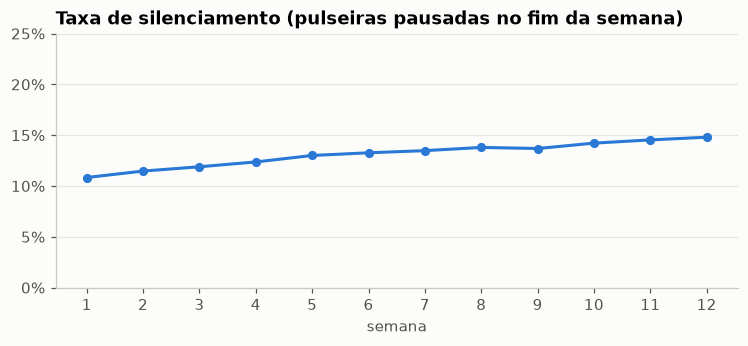

In [12]:
inter = pd.read_parquet(STAGING / "interesses.parquet")
status = pd.read_parquet(STAGING / "status.parquet")
tocou = dm.encontro_id.isin(inter.encontro_id)
t = dm.assign(tocou=tocou).groupby("conectou").tocou.mean()
print(f"Encontros com pelo menos um toque: {pct(tocou.mean())}")
print(f"  entre os que conectaram: {pct(t.loc[1])}   entre os que não conectaram: {pct(t.loc[0])}")
mutuo = inter.groupby("encontro_id").usuario_id.nunique().eq(2)
print(f"Toques mútuos (os dois tocaram -> revelação no app): {mutuo.sum():,} encontros")

ult = status.sort_values("ts").groupby("usuario_id").modo.last().value_counts(normalize=True)
print("\nModo de descoberta atual:", ", ".join(f"{k} {pct(v)}" for k, v in ult.items()))
semanas = pd.date_range("2026-07-06", periods=12, freq="7D")
pausados = []
for s in semanas:
    fim = s + pd.Timedelta(days=7)
    m = status[status.ts < fim].sort_values("ts").groupby("usuario_id").modo.last()
    pausados.append((m == "pausado").mean())
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, 13), pausados, color=AZUL, lw=2, marker="o", ms=5, zorder=2)
ax.set_xticks(range(1, 13)); eixo_pct(ax); ax.set_ylim(0, 0.25)
ax.set_title("Taxa de silenciamento (pulseiras pausadas no fim da semana)"); ax.set_xlabel("semana")
plt.show()

**Leitura.** O toque de interesse é um dado **simulado** (não é feature nem label). Aparece em ≈6% dos encontros e um pouco mais nos que são entre amigos (6,9% x 5,9%), diferença pequena e com poucos positivos (≈1,2 mil) — não deve ser lida como sinal. Toques mútuos (que levariam à revelação no app) são raros (147). A taxa de silenciamento (indicador da seção 3.2) vem só das trocas aleatórias de modo da simulação, sem relação com sinais da pulseira (o modelo ainda não existe). **A partir do CC7, ela vira o alerta de fadiga** — se subir mais rápido depois que a pulseira começar a sinalizar, os sinais estão demais.

## 8. Poder de cada feature e a referência mínima

Antes de qualquer modelo: quanto cada feature, **sozinha**, separa quem é amigo de quem não é (AUC univariada; 0,5 = nada, 1 = perfeito). Calculado só no **treino**. Agora o grupo "relação" está vazio (as variáveis de relação foram excluídas).

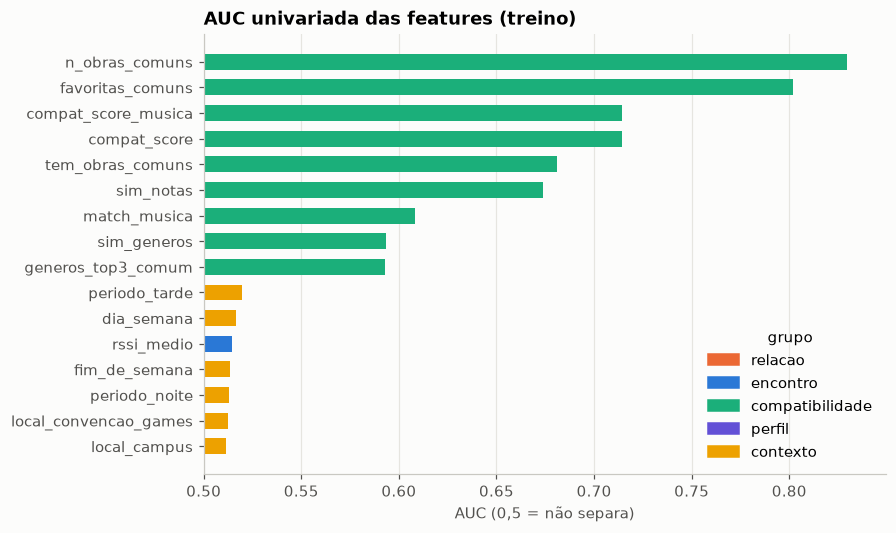

Pares de features muito correlacionadas (|r| > 0,8):


,,|r|
compat_score,compat_score_musica,1.00
n_encontros_anteriores_par,primeiro_encontro_par,0.98
horas_desde_ultimo_encontro_par,primeiro_encontro_par,0.94
compat_score,match_musica,0.94
compat_score_musica,match_musica,0.94
n_encontros_anteriores_par,horas_desde_ultimo_encontro_par,0.93
n_obras_comuns,favoritas_comuns,0.88
dia_semana,fim_de_semana,0.81


In [13]:
tr = dm[dm.split == "treino"]
cols = meta["colunas_features"]
auc = pd.Series({c: roc_auc_score(tr.conectou, tr[c]) for c in cols if tr[c].nunique() > 1})
forca = (auc - 0.5).abs() + 0.5
grupo = {c: g for g, cs in meta["grupos_features"].items() for c in cs}
grupo.update({c: "contexto" for c in cols if c.startswith(("local_", "periodo_"))})
top = forca.sort_values().tail(16)
cor_grupo = {"relacao": LARANJA, "encontro": AZUL, "compatibilidade": "#1baf7a", "perfil": "#6250d6", "contexto": "#eda100"}
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(np.arange(len(top)), top - 0.5, left=0.5, color=[cor_grupo[grupo[c]] for c in top.index], height=0.62, zorder=2)
ax.set_yticks(np.arange(len(top)), top.index); ax.set_xlim(0.5, max(0.6, float(top.max()) + 0.02))
ax.grid(axis="x", color="#e6e5e0"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=g) for g, c in cor_grupo.items()], loc="lower right", title="grupo")
ax.set_title("AUC univariada das features (treino)"); ax.set_xlabel("AUC (0,5 = não separa)")
plt.show()

alta = tr[cols].corr().abs().where(np.triu(np.ones((len(cols), len(cols)), dtype=bool), 1)).stack()
print("Pares de features muito correlacionadas (|r| > 0,8):")
display(alta[alta > 0.8].sort_values(ascending=False).round(2).to_frame("|r|"))

**Leitura.** As features mais fortes isoladamente são todas de **compatibilidade de gosto**: `n_obras_comuns` (AUC ≈ 0,83) e `favoritas_comuns` (≈ 0,80), seguidas de `compat_score` (≈ 0,71) e `sim_notas` (≈ 0,67). Duração, RSSI, contexto, dia e hora ficam em ≈ 0,50 — como esperado, já que os encontros são independentes da amizade. Há muita redundância dentro do bloco de gosto e do bloco de repetição (`compat_score` x `compat_score_musica` com |r| = 1,0; `n_obras_comuns` x `favoritas_comuns` com 0,88) → regularização ou seleção de features no CC3/CC4. A ordem das features descreve **esta simulação**, não é descoberta sobre usuários reais (ver `docs/validacao_simulacao.md`).

### Referência mínima (seção 4.5)

"Emitir sinal quando a compatibilidade passa de um limite." Medida na **validação** (split por par), é o número que o baseline do CC3 precisa superar.

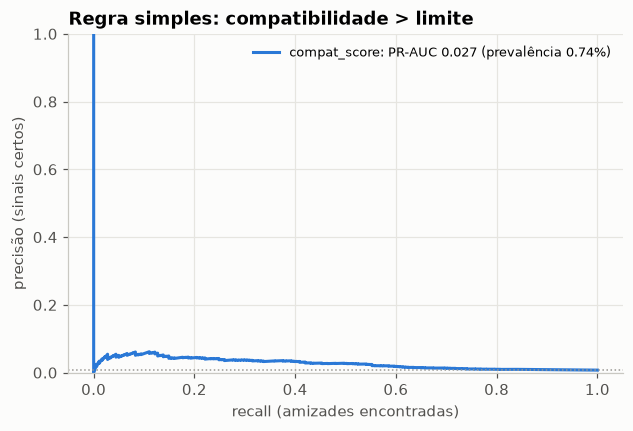

PR-AUC da regra na validação: 0.027 | prevalência: 0.0074 | razão: 3.6x


In [14]:
va = dm[dm.split == "validacao"]
fig, ax = plt.subplots(figsize=(6.5, 4))
p, r, _ = precision_recall_curve(va.conectou, va.compat_score)
ap = average_precision_score(va.conectou, va.compat_score)
ax.plot(r, p, color=AZUL, lw=2, label=f"compat_score: PR-AUC {ap:.3f} (prevalência {100 * va.conectou.mean():.2f}%)")
ax.axhline(va.conectou.mean(), color=CINZA, ls=":", lw=1)
ax.set_xlabel("recall (amizades encontradas)"); ax.set_ylabel("precisão (sinais certos)")
ax.set_title("Regra simples: compatibilidade > limite"); ax.legend(loc="upper right", fontsize=8.5); ax.set_ylim(0, 1)
ax.grid(axis="x", color="#e6e5e0")
plt.show()
print(f"PR-AUC da regra na validação: {ap:.3f} | prevalência: {va.conectou.mean():.4f} | razão: {ap / va.conectou.mean():.1f}x")

**Leitura.** A regra simples fica **acima do acaso, mas ainda em nível baixo em termos absolutos**: PR-AUC ≈ 0,027 contra prevalência de 0,74% (≈3,6× o acaso). A curva cai rápido: com precisão alta só se acha uma fração minúscula das amizades. Ou seja, acender a pulseira só por gosto parecido acerta pouco, embora muito melhor que sortear. Há espaço para o modelo do CC3 combinar `n_obras_comuns`, favoritas em comum, notas e gêneros — e comparar sempre contra esta regra e a prevalência.

## 9. Preparação dos dados e justificativas

O requisito do CC2 pede, além da EDA, as etapas de preparação — limpeza, tratamento de valores ausentes, encoding e normalização — e por que foram feitas assim. Todas rodam na DAG do Airflow (`opinion/pipeline/`); aqui mostramos o efeito de cada uma no dataset final.

In [15]:
etapas = pd.DataFrame([
    ("Limpeza (na chegada)", "Mensagens MQTT inválidas, duplicadas ou de pulseira de outra pessoa são rejeitadas pela ingestão e ficam registradas com o motivo",
     "Dados ruins não chegam ao modelo, mas continuam auditáveis"),
    ("Limpeza (no pipeline)", "A etapa de ingestão da DAG para se houver encontro duplicado, usuário desconhecido ou encontro consigo mesmo",
     "Melhor falhar alto do que treinar com dado inconsistente"),
    ("Sem informação do futuro", "Toda feature usa só dados de antes do início do encontro (teste automatizado em tests/)",
     "Seção 4.4: no uso real o modelo só conhece o passado"),
    ("Label", "conectou = 1 se o par é amigo no Last.fm; sempre disponível (nada fica pendente, nada é purgado)",
     "Rótulo real e estático; no modo interacao_48h os encontros recentes ficariam sem label"),
    ("Valores ausentes", "sim_notas sem obra em comum -> 0,5 + indicador tem_obras_comuns; sem encontro anterior -> 2016 h + indicador primeiro_encontro_par; modo desconhecido -> 'aberto'",
     "Ausência aqui é informação (nunca se encontraram, nada em comum), não erro: o indicador preserva isso"),
    ("Transformação", "Duração em log; perfil dos dois como mínimo e máximo",
     "Duração tem cauda longa; A/B é ordem arbitrária (quem publicou), min/max torna a feature simétrica"),
    ("Encoding", "One-hot em local e período; dia e hora mantidos numéricos",
     "Poucas categorias sem ordem natural -> one-hot; dia/hora têm efeito fraco, uma coluna basta"),
    ("Normalização", "NÃO aplicada no dataset; fica dentro do pipeline do modelo (StandardScaler ajustado só no treino de cada fold)",
     "Padronizar com média/desvio do dataset inteiro vazaria informação da validação e do teste para o treino"),
    ("Split por par", "70/15/15 por par, estratificado pelo rótulo (semente fixa): um par inteiro cai em treino, validação ou teste",
     "Como o rótulo é estático, um split temporal deixaria o mesmo par (mesmo rótulo) dos dois lados e inflaria a métrica"),
    ("Relação excluída", "algum_segue, seguem_mutuamente, interacoes_anteriores_par, interagiram_antes, conexoes_min/max ficam fora do modelo",
     "Com rótulo = amizade, a rede social seria o próprio rótulo (vazamento)"),
], columns=["Etapa", "O que é feito", "Por quê"])
with pd.option_context("display.max_colwidth", None):
    display(etapas.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Etapa,O que é feito,Por quê
Limpeza (na chegada),"Mensagens MQTT inválidas, duplicadas ou de pulseira de outra pessoa são rejeitadas pela ingestão e ficam registradas com o motivo","Dados ruins não chegam ao modelo, mas continuam auditáveis"
Limpeza (no pipeline),"A etapa de ingestão da DAG para se houver encontro duplicado, usuário desconhecido ou encontro consigo mesmo",Melhor falhar alto do que treinar com dado inconsistente
Sem informação do futuro,Toda feature usa só dados de antes do início do encontro (teste automatizado em tests/),Seção 4.4: no uso real o modelo só conhece o passado
Label,"conectou = 1 se o par é amigo no Last.fm; sempre disponível (nada fica pendente, nada é purgado)",Rótulo real e estático; no modo interacao_48h os encontros recentes ficariam sem label
Valores ausentes,"sim_notas sem obra em comum -> 0,5 + indicador tem_obras_comuns; sem encontro anterior -> 2016 h + indicador primeiro_encontro_par; modo desconhecido -> 'aberto'","Ausência aqui é informação (nunca se encontraram, nada em comum), não erro: o indicador preserva isso"
Transformação,Duração em log; perfil dos dois como mínimo e máximo,"Duração tem cauda longa; A/B é ordem arbitrária (quem publicou), min/max torna a feature simétrica"
Encoding,One-hot em local e período; dia e hora mantidos numéricos,"Poucas categorias sem ordem natural -> one-hot; dia/hora têm efeito fraco, uma coluna basta"
Normalização,NÃO aplicada no dataset; fica dentro do pipeline do modelo (StandardScaler ajustado só no treino de cada fold),Padronizar com média/desvio do dataset inteiro vazaria informação da validação e do teste para o treino
Split por par,"70/15/15 por par, estratificado pelo rótulo (semente fixa): um par inteiro cai em treino, validação ou teste","Como o rótulo é estático, um split temporal deixaria o mesmo par (mesmo rótulo) dos dois lados e inflaria a métrica"
Relação excluída,"algum_segue, seguem_mutuamente, interacoes_anteriores_par, interagiram_antes, conexoes_min/max ficam fora do modelo","Com rótulo = amizade, a rede social seria o próprio rótulo (vazamento)"


In [16]:
print("Valores ausentes tratados (todos os encontros):")
print(f"  sem artista avaliado em comum -> sim_notas = 0,5 ...... {(todos.n_obras_comuns == 0).sum():>7,} encontros")
print(f"  primeiro encontro do par -> horas_desde_ultimo = 2016 .. {todos.primeiro_encontro_par.sum():>7,} encontros")
print(f"Nulos restantes nas features do dataset do modelo: {int(dm[meta['colunas_features']].isna().sum().sum())}")
print()
print(f"Sem label ainda: {meta['encontros_sem_label_ainda']:,} | purgados na fronteira: {meta['encontros_purgados_fronteira']:,} (split por par: sem purga)")
print()
codificadas = [c for c in meta["colunas_features"] if c.startswith(("local_", "periodo_"))]
print("Colunas criadas pelo one-hot:", ", ".join(codificadas))

Valores ausentes tratados (todos os encontros):
  sem artista avaliado em comum -> sim_notas = 0,5 ......  70,636 encontros
  primeiro encontro do par -> horas_desde_ultimo = 2016 .. 153,213 encontros


Nulos restantes nas features do dataset do modelo: 0

Sem label ainda: 0 | purgados na fronteira: 0 (split por par: sem purga)

Colunas criadas pelo one-hot: local_campus, local_cinema, local_convencao_games, local_livraria, periodo_manha, periodo_noite, periodo_tarde


In [17]:
num = ["log_duracao", "rssi_medio", "horas_desde_ultimo_encontro_par", "historico_max", "sim_generos", "compat_score"]
display(dm.loc[dm.split == "treino", num].describe().T[["mean", "std", "min", "max"]].round(2))

,mean,std,min,max
log_duracao,5.28,0.91,3.40,9.42
rssi_medio,-62.89,4.49,-81.00,-42.90
horas_desde_ultimo_encontro_par,1934.29,343.93,0.65,2016.00
historico_max,49.98,0.68,1.00,50.00
sim_generos,0.27,0.28,0.00,1.00
compat_score,0.39,0.30,0.00,0.98


**Por que a normalização fica para o modelo.** As features têm escalas muito diferentes (horas chegam a ~2.000, similaridades ficam entre -1 e 1), então modelos sensíveis à escala — Regressão Logística com regularização, KNN — **precisam** de padronização. Mas ela deve ser *ajustada só no treino* e aplicada à validação e ao teste. Isso fica automático colocando o `StandardScaler` dentro de um `Pipeline` do scikit-learn, o que também vale para cada fold da validação cruzada (CC6):

```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo = make_pipeline(StandardScaler(), LogisticRegression())   # CC3
modelo.fit(X_treino, y_treino)   # média e desvio vêm só do treino
```

Árvores e Random Forest não dependem de escala, então o mesmo dataset serve para todos os modelos.

## 10. Conclusões

**Para o modelo (CC3 em diante)**

1. Problema **extremamente desbalanceado** (~0,76% positivos) → PR-AUC comparada com a prevalência; split **por par** (70/15/15) e validação cruzada agrupada por `par_id` (há 107 mil pares no treino; pares se repetem em ~6% dos encontros).
2. **Só o gosto carrega sinal:** artistas em comum, favoritos em comum e compatibilidade concentram as AUCs mais altas (0,67–0,83). Duração, RSSI, contexto, dia e hora ficam em ≈ 0,50, **porque o simulador os sorteia sem olhar a amizade** — não porque sejam inúteis na vida real.
3. Muita redundância entre features de gosto → regularização / seleção.
4. Features de relação (rede e interações) estão **excluídas**: com rótulo = amizade, seriam o próprio rótulo.
5. Referência a superar: regra de compatibilidade, PR-AUC ≈ 0,027 na validação (prevalência ≈ 0,74%).

**Para a sessão com o Design**

1. **A compatibilidade de gosto musical se associa à amizade real** (de ≈0,13% sem artistas em comum a ≈6% com 11 ou mais) — suporte ao aviso por afinidade de categoria.
2. **Contexto, duração e proximidade não mostram efeito aqui**: isso reflete a simulação, não a vida real. As políticas por contexto (seção 3.3) e a duração mínima precisam ser decididas com os encontros reais dos testes.
3. **Mesmo com forte afinidade, a amizade é rara** (≈2% no quintil mais compatível): o sinal da pulseira será de baixa precisão; vale pensar num gesto de baixo custo para o usuário.
4. As personas provisórias não explicam amizade → validar com as personas reais.

> Lembrete: usuários, gosto e amizades são reais (Last.fm 2011), mas **os encontros são simulados** e independentes da amizade, e o rótulo é uma amizade pré-existente, não uma conexão criada pelo encontro. A comparação com os encontros reais dos testes (semana 16) é o que dirá quanto disso se sustenta.